# Lecture 8.Data Wrangling: Join, Combine,and Reshape examples

## Hierarchical Indexing

In [1]:
import pandas as pd
import numpy as np
data = pd.Series(np.random.randn(9),
index=[['a', 'a', 'a', 'b', 'b', 'c', 'c', 'd', 'd'],
[1, 2, 3, 1, 3, 1, 2, 2, 3]])
data

a  1    1.522065
   2   -0.957434
   3    0.308334
b  1    1.142021
   3    1.274001
c  1   -0.250393
   2    0.044921
d  2   -1.237944
   3    0.279981
dtype: float64

In [2]:
data.index

MultiIndex([('a', 1),
            ('a', 2),
            ('a', 3),
            ('b', 1),
            ('b', 3),
            ('c', 1),
            ('c', 2),
            ('d', 2),
            ('d', 3)],
           )

In [3]:
data['b']

1    1.142021
3    1.274001
dtype: float64

In [4]:
data['b':'c']

b  1    1.142021
   3    1.274001
c  1   -0.250393
   2    0.044921
dtype: float64

In [5]:
data.loc[['b', 'd']]

b  1    1.142021
   3    1.274001
d  2   -1.237944
   3    0.279981
dtype: float64

In [6]:
data.loc[:, 2] #from an inner level

a   -0.957434
c    0.044921
d   -1.237944
dtype: float64

In [7]:
data

a  1    1.522065
   2   -0.957434
   3    0.308334
b  1    1.142021
   3    1.274001
c  1   -0.250393
   2    0.044921
d  2   -1.237944
   3    0.279981
dtype: float64

In [13]:
# you could rearrange the data into a DataFrame using its unstack method
data.unstack(level = 1, fill_value=0)

,1,2,3
a,1.522065,-0.957434,0.308334
b,1.142021,0.000000,1.274001
c,-0.250393,0.044921,0.000000
d,0.000000,-1.237944,0.279981


In [15]:
data.unstack().stack()

a  1    1.522065
   2   -0.957434
   3    0.308334
b  1    1.142021
   3    1.274001
c  1   -0.250393
   2    0.044921
d  2   -1.237944
   3    0.279981
dtype: float64

In [16]:
frame = pd.DataFrame(np.arange(12).reshape((4, 3)),
index=[['a', 'a', 'b', 'b'], [1, 2, 1, 2]],
columns=[['Ohio', 'Ohio', 'Colorado'],
['Green', 'Red', 'Green']])
frame

Ohio     Colorado
    Green Red    Green
a 1     0   1        2
  2     3   4        5
b 1     6   7        8
  2     9  10       11

In [17]:
frame.index.names = ['key1', 'key2']
frame.columns.names = ['state', 'color']
frame

state      Ohio     Colorado
color     Green Red    Green
key1 key2                   
a    1        0   1        2
     2        3   4        5
b    1        6   7        8
     2        9  10       11

In [ ]:
# frame[['Ohio','Colorado']]

## Reordering and Sorting Levels

In [18]:
frame

state      Ohio     Colorado
color     Green Red    Green
key1 key2                   
a    1        0   1        2
     2        3   4        5
b    1        6   7        8
     2        9  10       11

In [19]:
frame.swaplevel('key1', 'key2')

state      Ohio     Colorado
color     Green Red    Green
key2 key1                   
1    a        0   1        2
2    a        3   4        5
1    b        6   7        8
2    b        9  10       11

In [21]:
frame.sort_index(level=1)

state      Ohio     Colorado
color     Green Red    Green
key1 key2                   
a    1        0   1        2
b    1        6   7        8
a    2        3   4        5
b    2        9  10       11

In [22]:
frame

state      Ohio     Colorado
color     Green Red    Green
key1 key2                   
a    1        0   1        2
     2        3   4        5
b    1        6   7        8
     2        9  10       11

In [23]:
frame.swaplevel(0, 1).sort_index(level=0)

state      Ohio     Colorado
color     Green Red    Green
key2 key1                   
1    a        0   1        2
     b        6   7        8
2    a        3   4        5
     b        9  10       11

## Summary Statistics by Level

In [24]:
frame

state      Ohio     Colorado
color     Green Red    Green
key1 key2                   
a    1        0   1        2
     2        3   4        5
b    1        6   7        8
     2        9  10       11

In [25]:
frame.groupby(level='color',axis=1 ).sum()

color      Green  Red
key1 key2            
a    1         2    1
     2         8    4
b    1        14    7
     2        20   10

## Indexing with a DataFrame’s columns

In [26]:
frame = pd.DataFrame({'a': range(7), 'b': range(7, 0, -1),
'c': ['one', 'one', 'one', 'two', 'two',
'two', 'two'],
'd': [0, 1, 2, 0, 1, 2, 3]})
frame

,a,b,c,d
0,0,7,one,0
1,1,6,one,1
2,2,5,one,2
3,3,4,two,0
4,4,3,two,1
5,5,2,two,2
6,6,1,two,3


In [27]:
frame2 = frame.set_index(['c', 'd'])
frame2

a  b
c   d      
one 0  0  7
    1  1  6
    2  2  5
two 0  3  4
    1  4  3
    2  5  2
    3  6  1

In [28]:
frame.set_index(['c', 'd'], drop=False)

a  b    c  d
c   d              
one 0  0  7  one  0
    1  1  6  one  1
    2  2  5  one  2
two 0  3  4  two  0
    1  4  3  two  1
    2  5  2  two  2
    3  6  1  two  3

In [29]:
frame2

a  b
c   d      
one 0  0  7
    1  1  6
    2  2  5
two 0  3  4
    1  4  3
    2  5  2
    3  6  1

In [30]:
frame2.reset_index()

,c,d,a,b
0,one,0,0,7
1,one,1,1,6
2,one,2,2,5
3,two,0,3,4
4,two,1,4,3
5,two,2,5,2
6,two,3,6,1


# Combining and Merging Datasets

Data contained in pandas objects can be combined together in a number of ways:
- pandas.merge connects rows in DataFrames based on one or more keys. This will be familiar to users of SQL or other relational databases, as it implements database join operations.
- pandas.concat concatenates or “stacks” together objects along an axis.
- The combine_first instance method enables splicing together overlapping data to fill in missing values in one object with values from another.

## Database-Style DataFrame Joins

In [31]:
df1 = pd.DataFrame({'key': ['b', 'b', 'a', 'c', 'a', 'a', 'b'],
'data1': range(7)})
df1

,key,data1
0,b,0
1,b,1
2,a,2
3,c,3
4,a,4
5,a,5
6,b,6


In [32]:
df2 = pd.DataFrame({'key': ['a', 'b', 'd'],
'data2': range(3)})
df2

# abc  abd
# inner ab
# outer abcd
# right abd
# left  abc

,key,data2
0,a,0
1,b,1
2,d,2


In [33]:
pd.merge(df1, df2, how ="inner") #many-to-one join

,key,data1,data2
0,b,0,1
1,b,1,1
2,b,6,1
3,a,2,0
4,a,4,0
5,a,5,0


In [34]:
pd.merge(df1, df2, on='key')

,key,data1,data2
0,b,0,1
1,b,1,1
2,b,6,1
3,a,2,0
4,a,4,0
5,a,5,0


In [35]:
df3 = pd.DataFrame({'lkey': ['b', 'b', 'a', 'c', 'a', 'a', 'b'], 'data1': range(7)})
df4 = pd.DataFrame({'rkey': ['a', 'b', 'd'], 'data2': range(3)})
print(df3, "\n\n", df4)

  lkey  data1
0    b      0
1    b      1
2    a      2
3    c      3
4    a      4
5    a      5
6    b      6 

   rkey  data2
0    a      0
1    b      1
2    d      2


In [36]:
pd.merge(df3, df4, left_on='lkey', right_on='rkey') #By default merge does an 'inner' join

,lkey,data1,rkey,data2
0,b,0,b,1
1,b,1,b,1
2,b,6,b,1
3,a,2,a,0
4,a,4,a,0
5,a,5,a,0


In [ ]:
pd.merge(df1, df2, how='outer')  

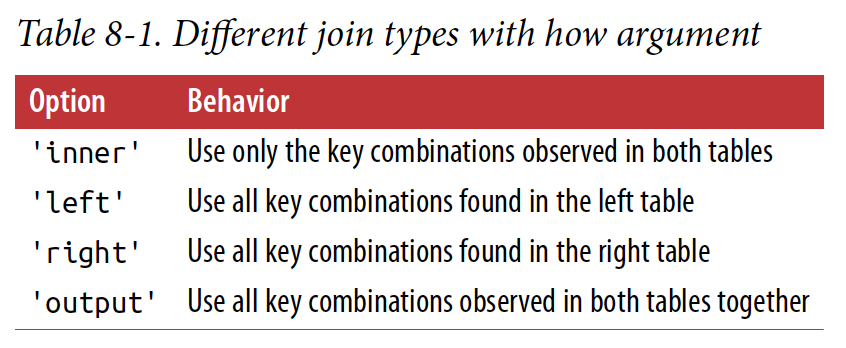

In [42]:
df1 = pd.DataFrame({'key': ['b', 'b', 'a', 'c', 'a', 'b'], 'data1': range(6)})
df2 = pd.DataFrame({'key': ['a', 'b', 'a', 'b', 'd'], 'data2': range(5)})
print(df1, "\n\n", df2)

  key  data1
0   b      0
1   b      1
2   a      2
3   c      3
4   a      4
5   b      5 

   key  data2
0   a      0
1   b      1
2   a      2
3   b      3
4   d      4


In [44]:
pd.merge(df1, df2, on='key', how='outer')

,key,data1,data2
0,b,0.0,1.0
1,b,0.0,3.0
2,b,1.0,1.0
3,b,1.0,3.0
4,b,5.0,1.0
5,b,5.0,3.0
6,a,2.0,0.0
7,a,2.0,2.0
8,a,4.0,0.0
9,a,4.0,2.0


In [ ]:
pd.merge(df1, df2, how='inner')

In [37]:
left = pd.DataFrame({'key1': ['foo', 'foo', 'bar'],
'key2': ['one', 'two', 'one'],
'lval': [1, 2, 3]})
left

,key1,key2,lval
0,foo,one,1
1,foo,two,2
2,bar,one,3


In [38]:
right = pd.DataFrame({'key1': ['foo', 'foo', 'bar', 'bar'],
'key2': ['one', 'one', 'one', 'two'],
'rval': [4, 5, 6, 7]})
right

,key1,key2,rval
0,foo,one,4
1,foo,one,5
2,bar,one,6
3,bar,two,7


In [39]:
pd.merge(left, right, on=['key1', 'key2'], how='inner')

,key1,key2,lval,rval
0,foo,one,1,4
1,foo,one,1,5
2,bar,one,3,6


In [40]:
pd.merge(left, right, on='key1')

,key1,key2_x,lval,key2_y,rval
0,foo,one,1,one,4
1,foo,one,1,one,5
2,foo,two,2,one,4
3,foo,two,2,one,5
4,bar,one,3,one,6
5,bar,one,3,two,7


In [41]:
pd.merge(left, right, on='key1', suffixes=('_left', '_right'))

,key1,key2_left,lval,key2_right,rval
0,foo,one,1,one,4
1,foo,one,1,one,5
2,foo,two,2,one,4
3,foo,two,2,one,5
4,bar,one,3,one,6
5,bar,one,3,two,7


## Merging on Index

In [45]:
left1 = pd.DataFrame({'key': ['a', 'b', 'a', 'a', 'b', 'c'], 'value': range(6)})
right1 = pd.DataFrame({'group_val': [3.5, 7]}, index=['a', 'b'])
print(left1, "\n\n", right1)

  key  value
0   a      0
1   b      1
2   a      2
3   a      3
4   b      4
5   c      5 

    group_val
a        3.5
b        7.0


In [46]:
pd.merge(left1, right1, left_on='key', right_index=True)

,key,value,group_val
0,a,0,3.5
2,a,2,3.5
3,a,3,3.5
1,b,1,7.0
4,b,4,7.0


In [47]:
pd.merge(left1, right1, left_on='key', right_index=True, how='outer')

,key,value,group_val
0,a,0,3.5
2,a,2,3.5
3,a,3,3.5
1,b,1,7.0
4,b,4,7.0
5,c,5,NaN


In [48]:
lefth = pd.DataFrame({'key1': ['Ohio', 'Ohio', 'Ohio',  'Nevada', 'Nevada'],
'key2': [2000, 2001, 2002, 2001, 2002],
'data': np.arange(5.)})
lefth

,key1,key2,data
0,Ohio,2000,0.0
1,Ohio,2001,1.0
2,Ohio,2002,2.0
3,Nevada,2001,3.0
4,Nevada,2002,4.0


In [49]:
righth = pd.DataFrame(np.arange(12).reshape((6, 2)),
 index=[['Nevada', 'Nevada', 'Ohio', 'Ohio','Ohio', 'Ohio'],
[2001, 2000, 2000, 2000, 2001, 2002]],
 columns=['event1', 'event2'])
righth

event1  event2
Nevada 2001       0       1
       2000       2       3
Ohio   2000       4       5
       2000       6       7
       2001       8       9
       2002      10      11

In [50]:
pd.merge(lefth, righth, left_on=['key1', 'key2'], right_index=True)

,key1,key2,data,event1,event2
0,Ohio,2000,0.0,4,5
0,Ohio,2000,0.0,6,7
1,Ohio,2001,1.0,8,9
2,Ohio,2002,2.0,10,11
3,Nevada,2001,3.0,0,1


In [ ]:
pd.merge(lefth, righth, left_on=['key1', 'key2'], right_index=True, how='outer')

In [51]:
left2 = pd.DataFrame([[1., 2.], [3., 4.], [5., 6.]],
index=['a', 'c', 'e'],
columns=['Ohio', 'Nevada'])

In [53]:
left2

,Ohio,Nevada
a,1.0,2.0
c,3.0,4.0
e,5.0,6.0


In [54]:
right2

,Missouri,Alabama
b,7.0,8.0
c,9.0,10.0
d,11.0,12.0
e,13.0,14.0


In [52]:
right2 = pd.DataFrame([[7., 8.], [9., 10.], [11., 12.], [13, 14]],
index=['b', 'c', 'd', 'e'],
columns=['Missouri', 'Alabama'])

In [55]:
pd.merge(left2, right2, how='outer', left_index=True, right_index=True)

,Ohio,Nevada,Missouri,Alabama
a,1.0,2.0,NaN,NaN
b,NaN,NaN,7.0,8.0
c,3.0,4.0,9.0,10.0
d,NaN,NaN,11.0,12.0
e,5.0,6.0,13.0,14.0


In [56]:
left2.join(right2, how='outer')

,Ohio,Nevada,Missouri,Alabama
a,1.0,2.0,NaN,NaN
b,NaN,NaN,7.0,8.0
c,3.0,4.0,9.0,10.0
d,NaN,NaN,11.0,12.0
e,5.0,6.0,13.0,14.0


In [57]:
left1.join(right1, on='key')

,key,value,group_val
0,a,0,3.5
1,b,1,7.0
2,a,2,3.5
3,a,3,3.5
4,b,4,7.0
5,c,5,NaN


In [58]:
another = pd.DataFrame([[7., 8.], [9., 10.], [11., 12.], [16., 17.]],
index=['a', 'c', 'e', 'f'],
columns=['New York', 'Oregon'])
another

,New York,Oregon
a,7.0,8.0
c,9.0,10.0
e,11.0,12.0
f,16.0,17.0


In [59]:
left2.join([right2, another])

,Ohio,Nevada,Missouri,Alabama,New York,Oregon
a,1.0,2.0,NaN,NaN,7.0,8.0
c,3.0,4.0,9.0,10.0,9.0,10.0
e,5.0,6.0,13.0,14.0,11.0,12.0


In [60]:
left2.join([right2, another], how='outer')

,Ohio,Nevada,Missouri,Alabama,New York,Oregon
a,1.0,2.0,NaN,NaN,7.0,8.0
c,3.0,4.0,9.0,10.0,9.0,10.0
e,5.0,6.0,13.0,14.0,11.0,12.0
b,NaN,NaN,7.0,8.0,NaN,NaN
d,NaN,NaN,11.0,12.0,NaN,NaN
f,NaN,NaN,NaN,NaN,16.0,17.0


# Concatenating Along an Axis

In [61]:
arr = np.arange(12).reshape((3, 4))
arr

array([[ 0,  1,  2,  3],
       [ 4,  5,  6,  7],
       [ 8,  9, 10, 11]])

In [63]:
np.concatenate([arr, arr], axis=1)

array([[ 0,  1,  2,  3,  0,  1,  2,  3],
       [ 4,  5,  6,  7,  4,  5,  6,  7],
       [ 8,  9, 10, 11,  8,  9, 10, 11]])

In [64]:
s1 = pd.Series([0, 1], index=['a', 'b'])
s2 = pd.Series([2, 3, 4], index=['c', 'd', 'e'])
s3 = pd.Series([5, 6], index=['f', 'g'])

In [71]:
pd.concat([s1, s2, s3],axis = 0)

a    0
b    1
c    2
d    3
e    4
f    5
g    6
dtype: int64

In [65]:
s1

a    0
b    1
dtype: int64

In [66]:
s3

f    5
g    6
dtype: int64

In [67]:
s2

c    2
d    3
e    4
dtype: int64

In [72]:
s4 = pd.concat([s1, s3])
s4

a    0
b    1
f    5
g    6
dtype: int64

In [73]:
pd.concat([s4, s1], axis=1)

,0,1
a,0,0.0
b,1,1.0
f,5,NaN
g,6,NaN


In [74]:
pd.concat([s1, s4], axis=1, join='inner')

,0,1
a,0,0
b,1,1


In [75]:
result = pd.concat([s1, s1, s3], keys=['one', 'two', 'three'])
# result = pd.concat([s1, s1, s3])
result

one    a    0
       b    1
two    a    0
       b    1
three  f    5
       g    6
dtype: int64

In [76]:
result.unstack()

,a,b,f,g
one,0.0,1.0,NaN,NaN
two,0.0,1.0,NaN,NaN
three,NaN,NaN,5.0,6.0


In [ ]:
pd.concat([s1, s2, s3], axis=1, keys=['one', 'two', 'three'])

In [ ]:
df1 = pd.DataFrame(np.arange(6).reshape(3, 2), index=['a', 'b', 'c'], columns=['one', 'two'])
df2 = pd.DataFrame(5 + np.arange(4).reshape(2, 2), index=['a', 'c'], columns=['three', 'four'])
print(df1,'\n\n',df2)

pd.concat([df1, df2], axis=1, keys=['level1', 'level2'])

In [ ]:
pd.concat({'level1': df1, 'level2': df2}, axis=1)

In [ ]:
pd.concat([df1, df2], axis=1, keys=['level1', 'level2'],names=['upper', 'lower'])

In [ ]:
df1 = pd.DataFrame(np.random.randn(3, 4), columns=['a', 'b', 'c', 'd'])
df2 = pd.DataFrame(np.random.randn(2, 3), columns=['b', 'd', 'a'])
print(df1,'\n\n',df2)
pd.concat([df1, df2], ignore_index=True)

## Combining Data with Overlap

In [77]:
a = pd.Series([np.nan, 2.5, np.nan, 3.5, 4.5, np.nan], index=['f', 'e', 'd', 'c', 'b', 'a'])
b = pd.Series(np.arange(len(a), dtype=np.float64), index=['f', 'e', 'd', 'c', 'b', 'a'])
b[-1] = np.nan
print(a,'\n\n',b)

f    NaN
e    2.5
d    NaN
c    3.5
b    4.5
a    NaN
dtype: float64 

 f    0.0
e    1.0
d    2.0
c    3.0
b    4.0
a    NaN
dtype: float64


In [78]:
np.where(pd.isnull(a), b, a)

array([0. , 2.5, 2. , 3.5, 4.5, nan])

In [80]:
b

f    0.0
e    1.0
d    2.0
c    3.0
b    4.0
a    NaN
dtype: float64

In [79]:
a

f    NaN
e    2.5
d    NaN
c    3.5
b    4.5
a    NaN
dtype: float64

In [81]:
a.combine_first(b)

f    0.0
e    2.5
d    2.0
c    3.5
b    4.5
a    NaN
dtype: float64

In [82]:
df1 = pd.DataFrame({'a': [1., np.nan, 5., np.nan], 'b': [np.nan, 2., np.nan, 6.], 'c': range(2, 18, 4)})
df2 = pd.DataFrame({'a': [5., 4., np.nan, 3., 7.], 'b': [np.nan, 3., 4., 6., 8.]})
print(df1,'\n\n',df2)

     a    b   c
0  1.0  NaN   2
1  NaN  2.0   6
2  5.0  NaN  10
3  NaN  6.0  14 

      a    b
0  5.0  NaN
1  4.0  3.0
2  NaN  4.0
3  3.0  6.0
4  7.0  8.0


In [83]:
df1.combine_first(df2)

,a,b,c
0,1.0,NaN,2.0
1,4.0,2.0,6.0
2,5.0,4.0,10.0
3,3.0,6.0,14.0
4,7.0,8.0,NaN


# Reshaping and Pivoting

## Reshaping with Hierarchical Indexing

In [ ]:
import pandas as pd
import numpy as np
data = pd.DataFrame(np.arange(6).reshape((2, 3)),
index=pd.Index(['Ohio', 'Colorado'], name='state'),
columns=pd.Index(['one', 'two', 'three'],
name='number'))
data

In [ ]:
result = data.stack()
result

In [ ]:
result.unstack()

In [ ]:
result.unstack(level = 0)

In [ ]:
result.unstack('state')

In [ ]:
s1 = pd.Series([0, 1, 2, 3], index=['a', 'b', 'c', 'd'])
s2 = pd.Series([4, 5, 6], index=['c', 'd', 'e'])
data2 = pd.concat([s1, s2], keys=['one', 'two'])
data2

In [ ]:
data2.unstack()

In [ ]:
data2.unstack().stack()

In [ ]:
data2.unstack().stack(dropna=False)

In [ ]:
df = pd.DataFrame({'left': result, 'right': result + 5}, columns=pd.Index(['left', 'right'], name='side'))
df

In [ ]:
df.unstack('state')

In [ ]:
df.unstack(0).stack('side')

# Pivoting “Long” to “Wide” Format

In [ ]:
path = '/Users/alimbekov/Desktop/Gaukhar/2025-2026/Python for Data Analysis/practice/examples/'
data = pd.read_csv(path+'macrodata.csv')
data.head()

In [ ]:
periods = pd.PeriodIndex(year=data.year, quarter=data.quarter,name='date')
periods

In [ ]:
columns = pd.Index(['realgdp', 'infl', 'unemp'], name='item')
columns

In [ ]:
data = data.reindex(columns=columns)
data

In [ ]:
data.index = periods.to_timestamp('D', 'end')
data

In [ ]:
ldata = data.stack().reset_index().rename(columns={0: 'value'})
ldata

In [ ]:
ldata[:10]

In [ ]:
pivoted = ldata.pivot('date', 'item', 'value')
pivoted

In [ ]:
ldata['value2'] = np.random.randn(len(ldata))
ldata[:10]

In [ ]:
pivoted = ldata.pivot('date', 'item')
pivoted

In [ ]:
pivoted['value'][:5]

## Pivoting “Wide” to “Long” Format

In [84]:
df = pd.DataFrame({'key': ['foo', 'bar', 'baz'],
'A': [1, 2, 3],
'B': [4, 5, 6],
'C': [7, 8, 9]})
df

,key,A,B,C
0,foo,1,4,7
1,bar,2,5,8
2,baz,3,6,9


In [85]:
melted = pd.melt(df, ['key'])
melted

,key,variable,value
0,foo,A,1
1,bar,A,2
2,baz,A,3
3,foo,B,4
4,bar,B,5
5,baz,B,6
6,foo,C,7
7,bar,C,8
8,baz,C,9


In [86]:
reshaped = melted.pivot('key', 'variable', 'value')
reshaped

variable,A,B,C
key,,,
bar,2,5,8
baz,3,6,9
foo,1,4,7


In [87]:
reshaped.reset_index()

variable,key,A,B,C
0,bar,2,5,8
1,baz,3,6,9
2,foo,1,4,7


In [ ]:
df

In [88]:
pd.melt(df, id_vars=['key'], value_vars=['A', 'B'])

,key,variable,value
0,foo,A,1
1,bar,A,2
2,baz,A,3
3,foo,B,4
4,bar,B,5
5,baz,B,6


In [89]:
pd.melt(df, value_vars=['A', 'B', 'C'])

,variable,value
0,A,1
1,A,2
2,A,3
3,B,4
4,B,5
5,B,6
6,C,7
7,C,8
8,C,9


In [90]:
pd.melt(df, value_vars=['key', 'A', 'B'])

,variable,value
0,key,foo
1,key,bar
2,key,baz
3,A,1
4,A,2
5,A,3
6,B,4
7,B,5
8,B,6


Hierarchical Indexing

concat(), merge(), join(), melt(), pivot()
stack(), unstack(), combine_first()

Types of join: inner, outer, left,right   